Data Science Case Study: Statistical Analysis of Virat Kohli   

Data Analysis, Preprocessing, Exploratory Data Analysis (EDA) & Visualization
TA Activity Project

This notebook analyzes two datasets:

1.Virat Kohli DataSet.csv — innings-level batting statistics.

2.Virat-Kohli-International-Cricket-Centuries.csv — international century records.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


print("Libraries imported successfully.")

Libraries imported successfully.


In [7]:
df = pd.read_csv("Virat Kohli DataSet.csv")
centuries = pd.read_csv("Virat-Kohli-International-Cricket-Centuries.csv")

In [10]:
df.head()


,Runs,BF,4s,6s,SR,Pos,Dismissal,Inns,Opposition,Ground,Start Date
0,12,22,1,0,54.54,2.0,lbw,1,v Sri Lanka,Dambulla,18-Aug-08
1,37,67,6,0,55.22,2.0,caught,2,v Sri Lanka,Dambulla,20-Aug-08
2,25,38,4,0,65.78,1.0,run out,1,v Sri Lanka,Colombo (RPS),24-Aug-08
3,54,66,7,0,81.81,1.0,bowled,1,v Sri Lanka,Colombo (RPS),27-Aug-08
4,31,46,3,1,67.39,1.0,lbw,2,v Sri Lanka,Colombo (RPS),29-Aug-08


In [11]:
centuries.head()

,No.,Runs,Against,Position,Innings,Venue,Ground,Date,Result
0,1,107,Sri Lanka,4,2,"Eden Gardens, Kolkata",Home,24-Dec-09,Won
1,2,102*,Bangladesh,3,2,"Sher-e-Bangla Cricket Stadium, Dhaka",Away,11-Jan-10,Won
2,3,118,Australia,3,2,"APCA-VDCA Stadium, Visakhapatnam",Home,20-Oct-10,Won
3,4,105,New Zealand,3,1,"Nehru Stadium, Guwahati",Home,28-Nov-10,Won
4,5,100*,Bangladesh,4,1,"Sher-e-Bangla Cricket Stadium, Dhaka",Away,19-Feb-11,Won


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 132 entries, 0 to 131
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Runs        132 non-null    int64  
 1   BF          132 non-null    int64  
 2   4s          132 non-null    int64  
 3   6s          132 non-null    int64  
 4   SR          132 non-null    float64
 5   Pos         132 non-null    float64
 6   Dismissal   132 non-null    object 
 7   Inns        132 non-null    int64  
 8   Opposition  132 non-null    object 
 9   Ground      132 non-null    object 
 10  Start Date  132 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 11.5+ KB


In [12]:
centuries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   No.       80 non-null     int64 
 1   Runs      80 non-null     object
 2   Against   80 non-null     object
 3   Position  80 non-null     int64 
 4   Innings   80 non-null     int64 
 5   Venue     80 non-null     object
 6   Ground    79 non-null     object
 7   Date      80 non-null     object
 8   Result    80 non-null     object
dtypes: int64(3), object(6)
memory usage: 5.8+ KB


In [5]:
df.isnull().sum()

Runs          0
BF            0
4s            0
6s            0
SR            0
Pos           0
Dismissal     0
Inns          0
Opposition    0
Ground        0
Start Date    0
dtype: int64

In [13]:
df.isnull().sum()

Runs          0
BF            0
4s            0
6s            0
SR            0
Pos           0
Dismissal     0
Inns          0
Opposition    0
Ground        0
Start Date    0
dtype: int64

In [6]:
df.shape

(132, 11)

In [14]:
centuries.shape

(80, 9)

In [54]:
centuries.value_counts()

No.  Runs  Against      Position  Innings  Venue                                          Ground   Date        Result  Year    Not Out
1    107   Sri Lanka    4         2        Eden Gardens, Kolkata                          Home     2009-12-24  Won     2009.0  True       1
2    102   Bangladesh   3         2        Sher-e-Bangla Cricket Stadium, Dhaka           Away     2010-01-11  Won     2010.0  True       1
3    118   Australia    3         2        APCA-VDCA Stadium, Visakhapatnam               Home     2010-10-20  Won     2010.0  True       1
4    105   New Zealand  3         1        Nehru Stadium, Guwahati                        Home     2010-11-28  Won     2010.0  True       1
5    100   Bangladesh   4         1        Sher-e-Bangla Cricket Stadium, Dhaka           Away     2011-02-19  Won     2011.0  True       1
                                                                                                                                         ..
75   186   Australia    4

In [55]:
df.value_counts()

Runs  BF   4s  6s  SR      Pos  Dismissal  Inns  Opposition      Ground         Start Date  Year  Boundary Runs  Non-Boundary Runs  Balls per Run  Runs 50 Plus  Runs 100 Plus
1     3    0   0   33.33   3.0  not out    2     v England       Birmingham     2014-09-02  2014  0              1                  3.000000       False         False            1
                           7.0  caught     1     v South Africa  Nagpur         2011-03-12  2011  0              1                  3.000000       False         False            1
      4    0   0   25.00   3.0  caught     2     v Bangladesh    Dhaka          2015-06-18  2015  0              1                  4.000000       False         False            1
      5    0   0   20.00   3.0  caught     1     v Sri Lanka     Hambantota     2012-07-24  2012  0              1                  5.000000       False         False            1
      13   0   0   7.69    3.0  caught     2     v Australia     Sydney         2015-03-26  2015  0      

In [15]:
print("\\nInnings dataset descriptive statistics:")
display(df.describe())

print("\\nCentury dataset descriptive statistics:")
display(centuries.describe())

\nInnings dataset descriptive statistics:


,Runs,BF,4s,6s,SR,Pos,Inns
count,132.000000,132.000000,132.000000,132.000000,132.000000,132.000000,132.000000
mean,46.848485,50.871212,4.371212,0.545455,76.991212,3.303030,1.575758
std,41.994635,38.729716,4.404032,1.086795,37.874491,0.873174,0.496110
min,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
25%,10.000000,17.750000,1.000000,0.000000,61.702500,3.000000,1.000000
50%,32.500000,42.500000,3.000000,0.000000,78.710000,3.000000,2.000000
75%,80.250000,82.250000,7.000000,1.000000,100.000000,4.000000,2.000000
max,154.000000,140.000000,18.000000,7.000000,209.090000,7.000000,2.000000


\nCentury dataset descriptive statistics:


,No.,Position,Innings
count,80.0000,80.000000,80.00000
mean,40.5000,3.500000,1.67500
std,23.2379,0.656033,0.67082
min,1.0000,2.000000,1.00000
25%,20.7500,3.000000,1.00000
50%,40.5000,3.000000,2.00000
75%,60.2500,4.000000,2.00000
max,80.0000,6.000000,4.00000


In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
centuries.duplicated().sum()

np.int64(0)

DATA PREPROCESSING AND FEATURE ENGINEERING

In [18]:
df = df.copy()
centuries = centuries.copy()

df.columns = df.columns.str.strip()
centuries.columns = centuries.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

for col in centuries.select_dtypes(include="object").columns:
    centuries[col] = centuries[col].str.strip()



In [24]:
df["Start Date"] = pd.to_datetime(df["Start Date"], format="%d-%b-%y", errors="coerce")
centuries["Date"] = pd.to_datetime(centuries["Date"], format="%d-%b-%y", errors="coerce")

In [25]:
df["Pos"] = pd.to_numeric(df["Pos"], errors="coerce")
df["Year"] = df["Start Date"].dt.year
centuries["Year"] = centuries["Date"].dt.year

In [26]:
df["Boundary Runs"] = df["4s"] * 4 + df["6s"] * 6
df["Non-Boundary Runs"] = df["Runs"] - df["Boundary Runs"]
df["Balls per Run"] = np.where(df["Runs"] > 0, df["BF"] / df["Runs"], np.nan)
df["Runs 50 Plus"] = df["Runs"] >= 50
df["Runs 100 Plus"] = df["Runs"] >= 100

In [27]:
centuries["Not Out"] = centuries["Runs"].astype(str).str.contains(r"\\*", regex=True)
centuries["Runs"] = pd.to_numeric(
    centuries["Runs"].astype(str).str.replace("*", "", regex=False),
    errors="coerce"
)
centuries["Ground"] = centuries["Ground"].fillna("Unknown")

In [23]:
print("Preprocessing complete.")
print("Innings dates that could not be parsed:", df["Start Date"].isna().sum())
print("Century dates that could not be parsed:", centuries["Date"].isna().sum())
display(df.head())
display(centuries.head())

Preprocessing complete.
Innings dates that could not be parsed: 0
Century dates that could not be parsed: 1


,Runs,BF,4s,6s,SR,Pos,Dismissal,Inns,Opposition,Ground,Start Date,Year,Boundary Runs,Non-Boundary Runs,Balls per Run,Runs 50 Plus,Runs 100 Plus
0,12,22,1,0,54.54,2.0,lbw,1,v Sri Lanka,Dambulla,2008-08-18,2008,4,8,1.833333,False,False
1,37,67,6,0,55.22,2.0,caught,2,v Sri Lanka,Dambulla,2008-08-20,2008,24,13,1.810811,False,False
2,25,38,4,0,65.78,1.0,run out,1,v Sri Lanka,Colombo (RPS),2008-08-24,2008,16,9,1.520000,False,False
3,54,66,7,0,81.81,1.0,bowled,1,v Sri Lanka,Colombo (RPS),2008-08-27,2008,28,26,1.222222,True,False
4,31,46,3,1,67.39,1.0,lbw,2,v Sri Lanka,Colombo (RPS),2008-08-29,2008,18,13,1.483871,False,False


,No.,Runs,Against,Position,Innings,Venue,Ground,Date,Result,Year,Not Out
0,1,107,Sri Lanka,4,2,"Eden Gardens, Kolkata",Home,2009-12-24,Won,2009.0,True
1,2,102,Bangladesh,3,2,"Sher-e-Bangla Cricket Stadium, Dhaka",Away,2010-01-11,Won,2010.0,True
2,3,118,Australia,3,2,"APCA-VDCA Stadium, Visakhapatnam",Home,2010-10-20,Won,2010.0,True
3,4,105,New Zealand,3,1,"Nehru Stadium, Guwahati",Home,2010-11-28,Won,2010.0,True
4,5,100,Bangladesh,4,1,"Sher-e-Bangla Cricket Stadium, Dhaka",Away,2011-02-19,Won,2011.0,True


EDA

Distribution of runs — histogram and KDE¶

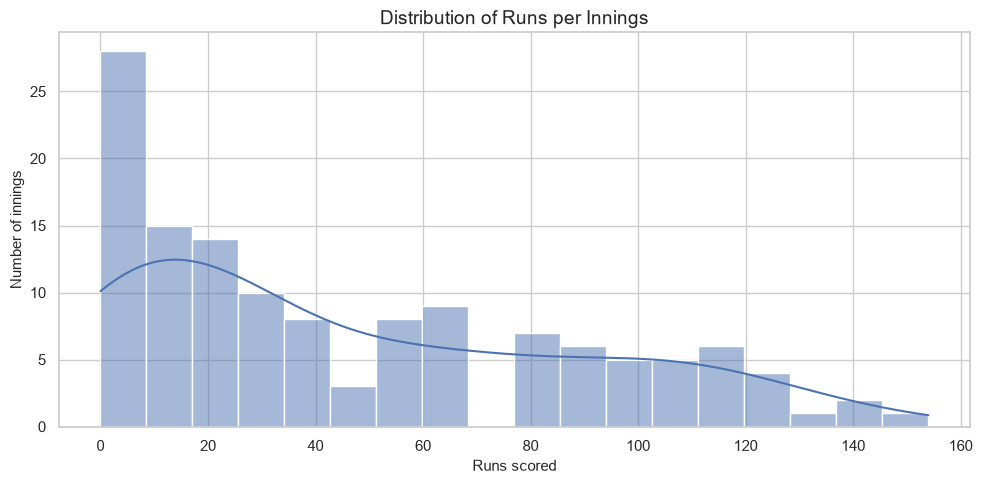

In [31]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="Runs", bins=18, kde=True)
plt.title("Distribution of Runs per Innings")
plt.xlabel("Runs scored")
plt.ylabel("Number of innings")
plt.tight_layout()
plt.show()

 Average, median and highest score summary

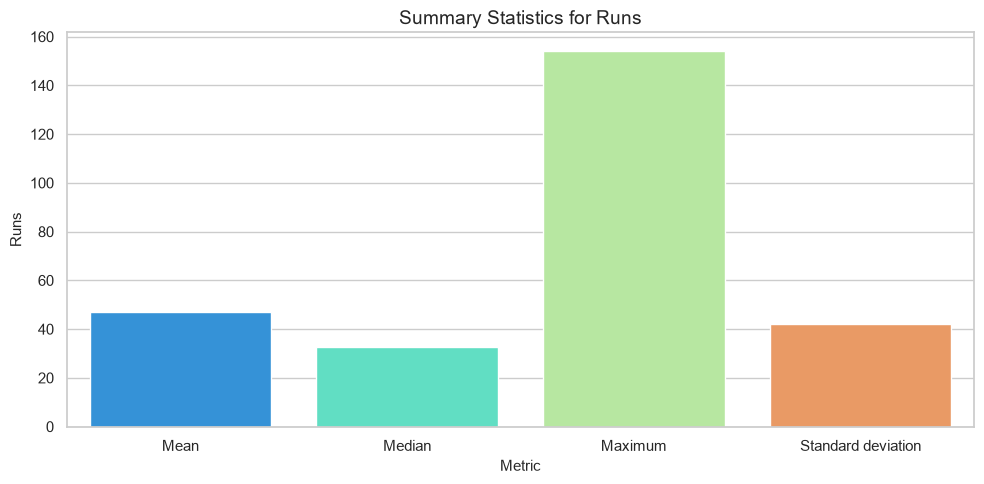

In [35]:
summary = pd.DataFrame({
    "Metric": ["Mean", "Median", "Maximum", "Standard deviation"],
    "Runs": [df["Runs"].mean(), df["Runs"].median(), df["Runs"].max(), df["Runs"].std()]
})
sns.barplot(data=summary, x="Metric", y="Runs",palette="rainbow")
plt.title("Summary Statistics for Runs")
plt.ylabel("Runs")
plt.tight_layout()
plt.show()


In [34]:
display(summary)

,Metric,Runs
0,Mean,46.848485
1,Median,32.500000
2,Maximum,154.000000
3,Standard deviation,41.994635


Box plot of runs

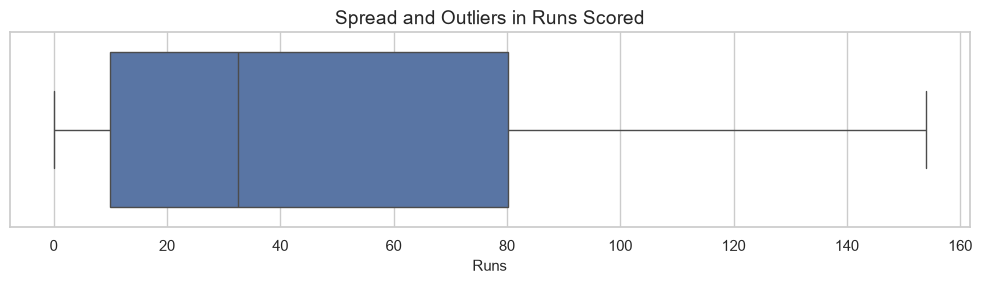

In [38]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=df["Runs"])
plt.title("Spread and Outliers in Runs Scored")
plt.xlabel("Runs")
plt.tight_layout()
plt.show()

 Runs by batting position — box plot

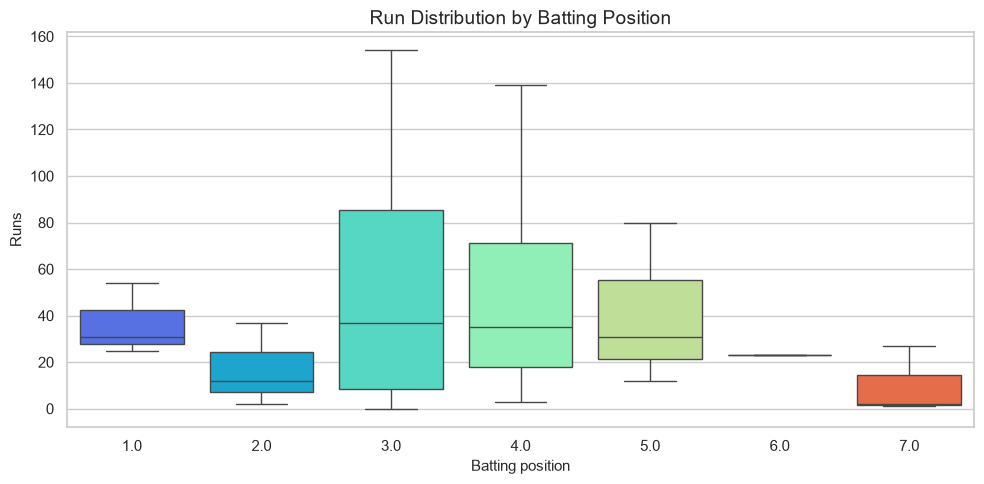

In [40]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Pos", y="Runs",palette="rainbow")
plt.title("Run Distribution by Batting Position")
plt.xlabel("Batting position")
plt.ylabel("Runs")
plt.tight_layout()
plt.show()

Number of innings by batting position

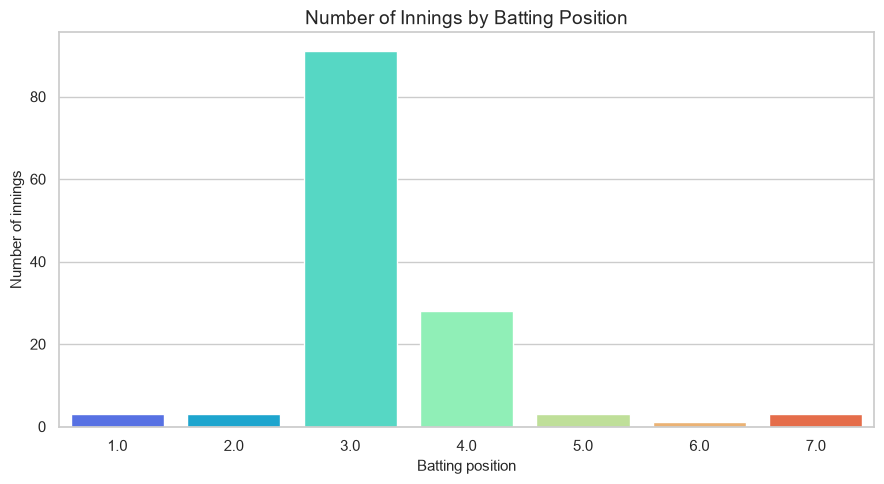

In [41]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="Pos", order=sorted(df["Pos"].dropna().unique()),palette="rainbow")
plt.title("Number of Innings by Batting Position")
plt.xlabel("Batting position")
plt.ylabel("Number of innings")
plt.tight_layout()
plt.show()

Runs by innings number

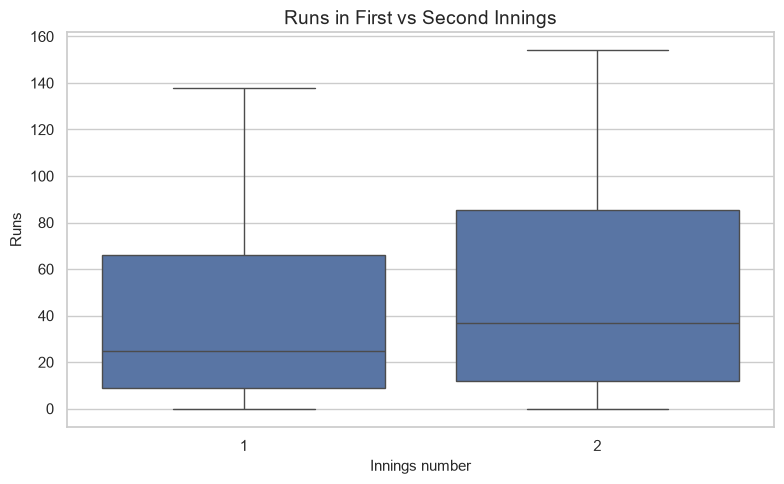

In [58]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Inns", y="Runs")
plt.title("Runs in First vs Second Innings")
plt.xlabel("Innings number")
plt.ylabel("Runs")
plt.tight_layout()
plt.show()

Strike rate distribution

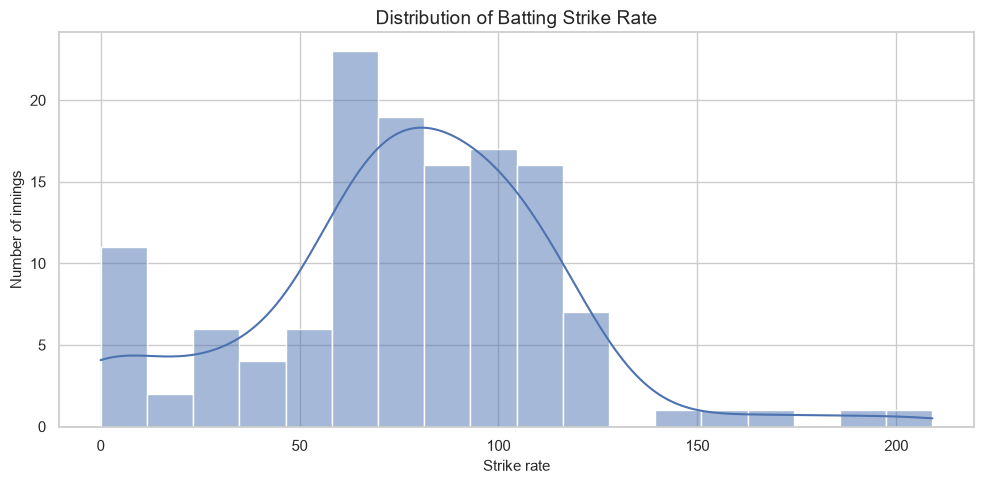

In [60]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="SR", bins=18, kde=True)
plt.title("Distribution of Batting Strike Rate")
plt.xlabel("Strike rate")
plt.ylabel("Number of innings")
plt.tight_layout()
plt.show()

Runs vs balls faced

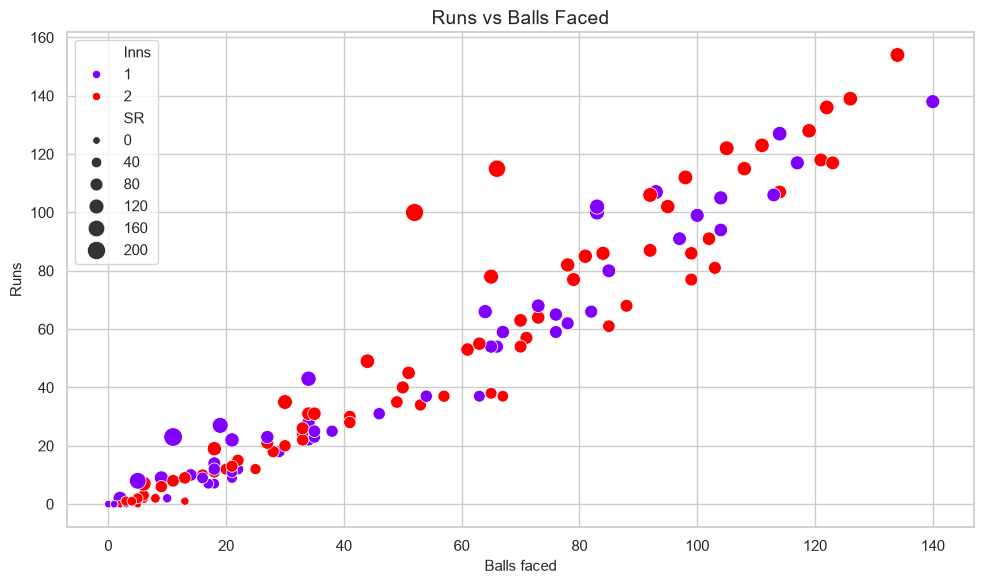

In [62]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="BF", y="Runs", hue="Inns", size="SR", sizes=(30, 180),palette="rainbow")
plt.title("Runs vs Balls Faced")
plt.xlabel("Balls faced")
plt.ylabel("Runs")
plt.tight_layout()
plt.show()

Runs vs strike rate

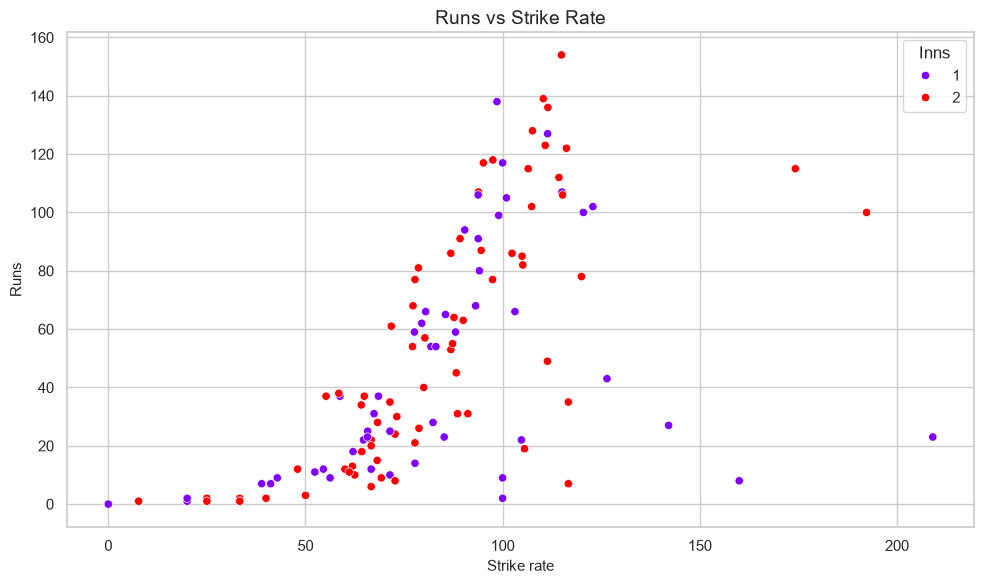

In [64]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="SR", y="Runs", hue="Inns", palette="rainbow")
plt.title("Runs vs Strike Rate")
plt.xlabel("Strike rate")
plt.ylabel("Runs")
plt.tight_layout()
plt.show()

 Boundary runs vs non-boundary runs

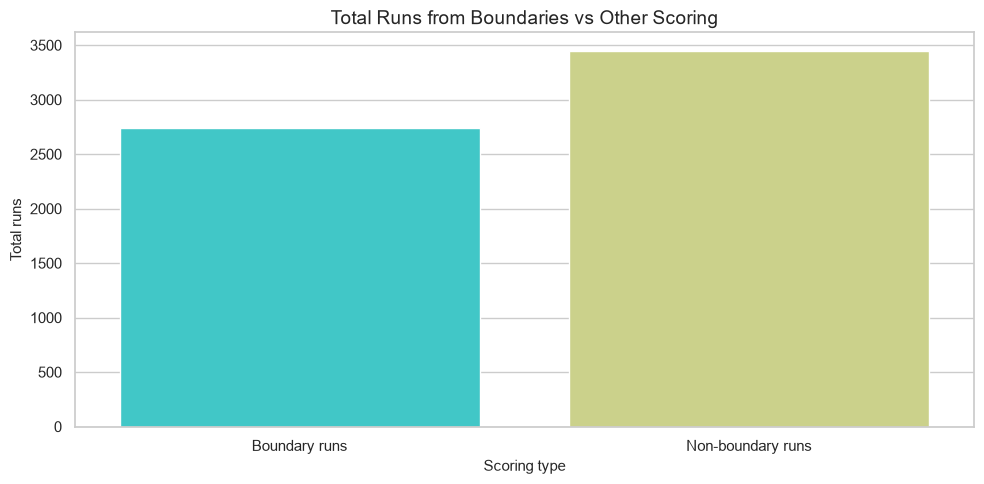

In [67]:
boundary_summary = pd.DataFrame({
    "Scoring type": ["Boundary runs", "Non-boundary runs"],
    "Runs": [df["Boundary Runs"].sum(), df["Non-Boundary Runs"].sum()]
})
sns.barplot(data=boundary_summary, x="Scoring type", y="Runs",palette="rainbow")
plt.title("Total Runs from Boundaries vs Other Scoring")
plt.ylabel("Total runs")
plt.tight_layout()
plt.show()


In [66]:
display(boundary_summary)

,Scoring type,Runs
0,Boundary runs,2740
1,Non-boundary runs,3444


Percentage Distribution of Dismissal Types

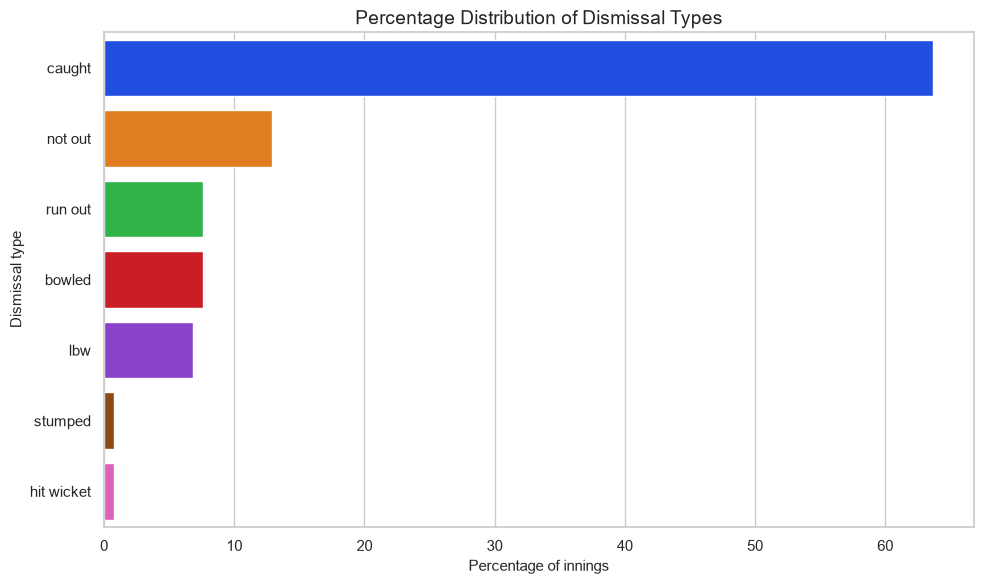

In [69]:
dismissal_pct = df["Dismissal"].value_counts(normalize=True).mul(100).rename_axis("Dismissal").reset_index(name="Percentage")
plt.figure(figsize=(10, 6))
sns.barplot(data=dismissal_pct, x="Percentage", y="Dismissal",palette="bright")
plt.title("Percentage Distribution of Dismissal Types")
plt.xlabel("Percentage of innings")
plt.ylabel("Dismissal type")
plt.tight_layout()
plt.show()


In [70]:
display(dismissal_pct)

,Dismissal,Percentage
0,caught,63.636364
1,not out,12.878788
2,run out,7.575758
3,bowled,7.575758
4,lbw,6.818182
5,stumped,0.757576
6,hit wicket,0.757576


Average runs against opponents

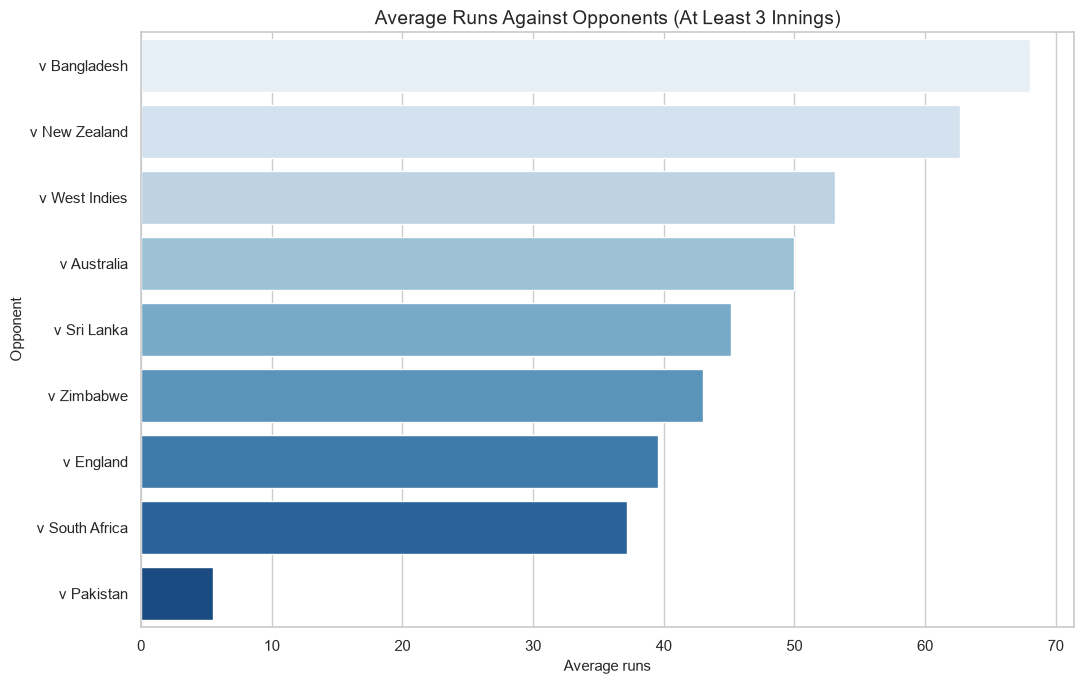

In [74]:
opponent_stats = df.groupby("Opposition").agg(
    Innings=("Runs", "size"),
    Average_Runs=("Runs", "mean"),
    Median_Runs=("Runs", "median"),
    Highest_Score=("Runs", "max")
).query("Innings >= 3").sort_values("Average_Runs", ascending=False)

plt.figure(figsize=(11, 7))
sns.barplot(data=opponent_stats.reset_index(), x="Average_Runs", y="Opposition",palette="Blues")
plt.title("Average Runs Against Opponents (At Least 3 Innings)")
plt.xlabel("Average runs")
plt.ylabel("Opponent")
plt.tight_layout()
plt.show()


In [72]:
display(opponent_stats)

,Innings,Average_Runs,Median_Runs,Highest_Score
Opposition,,,,
v Bangladesh,8,68.000000,78.5,136
v New Zealand,14,62.642857,64.5,154
v West Indies,19,53.105263,59.0,127
v Australia,20,49.950000,30.5,118
v Sri Lanka,24,45.166667,36.0,139
v Zimbabwe,5,43.000000,18.0,115
v England,21,39.523810,35.0,122
v South Africa,15,37.200000,28.0,138
v Pakistan,4,5.500000,6.5,9


Yearly average runs

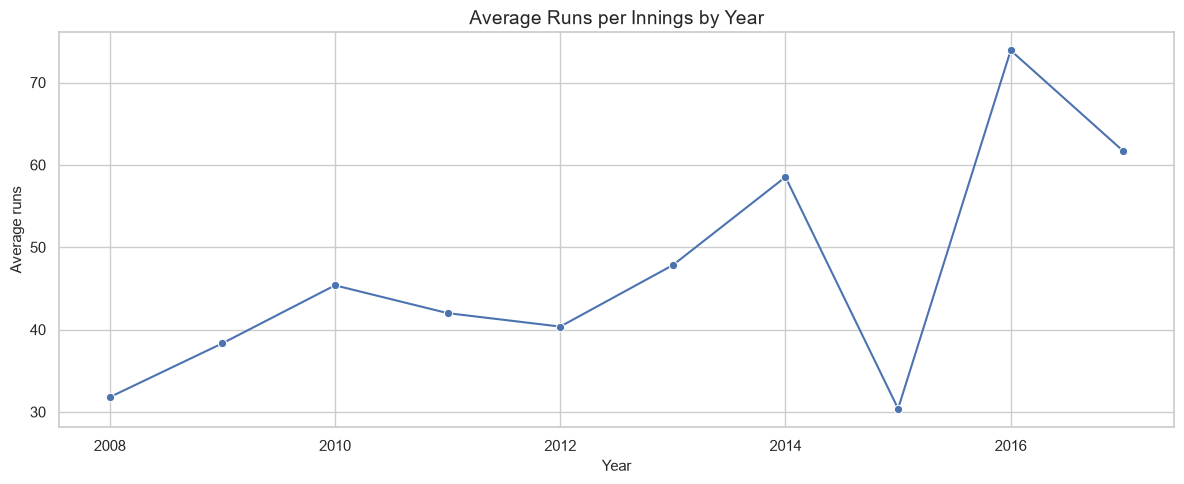

In [75]:
yearly = df.groupby("Year", dropna=True).agg(
    Innings=("Runs", "size"),
    Total_Runs=("Runs", "sum"),
    Average_Runs=("Runs", "mean"),
    Median_Runs=("Runs", "median"),
    Average_SR=("SR", "mean")
).reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=yearly, x="Year", y="Average_Runs", marker="o")
plt.title("Average Runs per Innings by Year")
plt.xlabel("Year")
plt.ylabel("Average runs")
plt.tight_layout()
plt.show()


In [76]:
display(yearly)

,Year,Innings,Total_Runs,Average_Runs,Median_Runs,Average_SR
0,2008,5,159,31.800000,31.0,64.948000
1,2009,6,230,38.333333,28.5,92.448333
2,2010,16,726,45.375000,34.0,64.133125
3,2011,31,1302,42.000000,28.0,73.765161
4,2012,11,444,40.363636,23.0,64.293636
5,2013,23,1100,47.826087,37.0,83.085652
6,2014,17,995,58.529412,53.0,81.761176
7,2015,10,304,30.400000,11.5,66.631000
8,2016,10,739,73.900000,75.0,93.262000
9,2017,3,185,61.666667,55.0,121.163333


Correlation heatmap

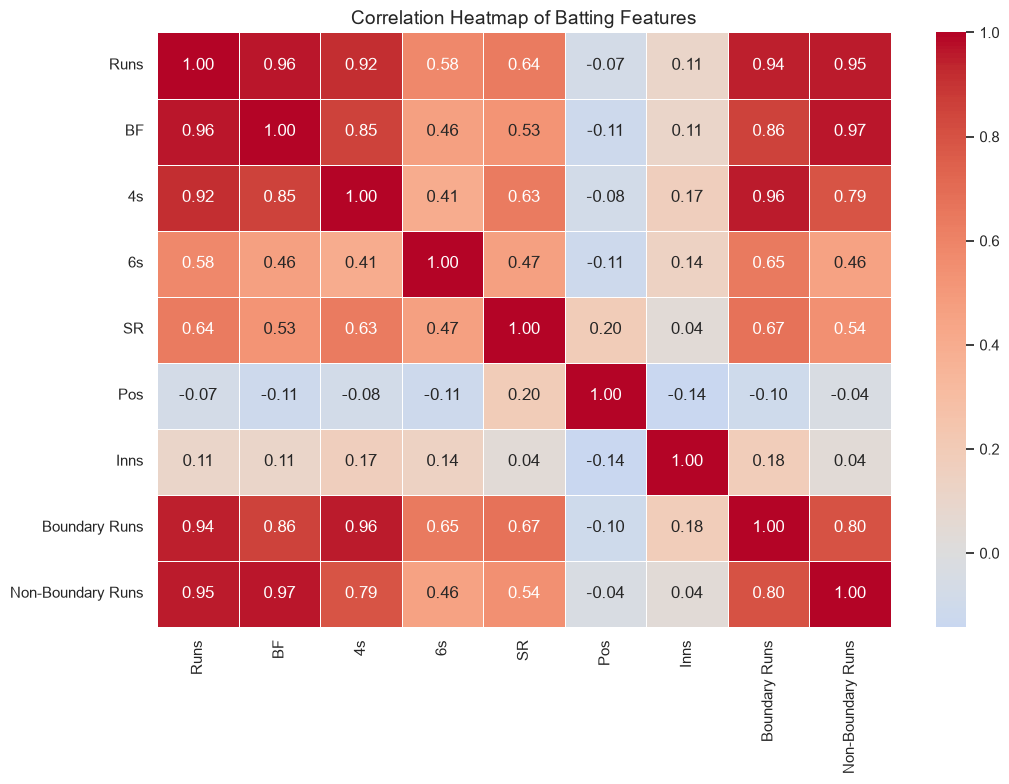

In [77]:
numeric_features = [
    "Runs", "BF", "4s", "6s", "SR", "Pos", "Inns",
    "Boundary Runs", "Non-Boundary Runs"
]
corr = df[numeric_features].corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Batting Features")
plt.tight_layout()
plt.show()